In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False


In [ ]:
def generate_single_measurement_curves(sample):

    sample_short, block = BM29.extract_sample_name(sample)
    sample_path = BM29.blockpath(block) / sample
    print(sample, sample_path)

    buffer_0_path = sample_path / "buffer_0"
    buffer_1_path = sample_path / "buffer_1"
    sample_dat_path = sample_path / "sample" 

    relevant_paths = [buffer_0_path, buffer_1_path, sample_dat_path]

    for path in relevant_paths: 
        dat_files = list(path.glob("*.dat"))
        fixed_xlim = (3e-2, 6)
        fixed_ylim = (1e-2, 1)
        if path == buffer_1_path:
            for i, file in enumerate(dat_files):
                try:
                    # Try comma-separated format
                    q, I, Ierr = np.loadtxt(
                        file,
                        delimiter=",",
                        skiprows=1,
                        unpack=True
                    )
                except ValueError:
                    # Fall back to whitespace-separated format with # comments
                    q, I, Ierr = np.loadtxt(
                        file,
                        comments="#",
                        unpack=True
                        )
                plt.figure(figsize=(12, 7.5))
                plt.errorbar(q, I, Ierr, ls = "None", marker="o")
                plt.xlabel("$q$")
                plt.ylabel("$I$")
                plt.xscale("log")
                plt.yscale("log")
                plt.title(BM29.sample_dict[sample_short] + "  " + file.stem)
                plt.xlim(fixed_xlim)
                plt.ylim(fixed_ylim)
                picture_folder = sample_path / "curves"
                if not picture_folder.exists():
                    picture_folder.mkdir()
                plt.savefig(picture_folder / (file.stem + f"post_{i}" + ".png"), dpi = 70)
                plt.close()
        else:
            for file in dat_files:
                try:
                    # Try comma-separated format
                    q, I, Ierr = np.loadtxt(
                        file,
                        delimiter=",",
                        skiprows=1,
                        unpack=True
                    )
                except ValueError:
                    # Fall back to whitespace-separated format with # comments
                    q, I, Ierr = np.loadtxt(
                        file,
                        comments="#",
                        unpack=True
                        )  
                plt.figure(figsize=(12, 7.5))
                plt.errorbar(q, I, Ierr, ls = "None", marker="o")
                plt.xlabel("$q$")
                plt.ylabel("$I$")
                plt.xscale("log")
                plt.yscale("log")
                plt.title(BM29.sample_dict[sample_short] + "  " + file.stem)
                plt.xlim(fixed_xlim)
                plt.ylim(fixed_ylim)
                picture_folder = sample_path / "curves"
                if not picture_folder.exists():
                    picture_folder.mkdir()
                plt.savefig(picture_folder / (file.stem + ".png"), dpi = 70)
                plt.close()
    return 


def average_dat_files(dat_files):
    """
    Each .dat file must have three columns: q, I, sigma_I.
    Returns q, I_avg, sigma_avg arrays.
    """
    data = [np.loadtxt(f, comments="#") for f in dat_files]
    q = data[0][:, 0]
    I = np.array([d[:, 1] for d in data])
    sigma = np.array([d[:, 2] for d in data])
    sigma[sigma <= 1e-10] = 1e-10

    # weighted average: weights = 1 / sigma^2
    w = 1 / sigma**2
    I_avg = np.sum(I * w, axis=0) / np.sum(w, axis=0)
    sigma_avg = np.sqrt(1 / np.sum(w, axis=0))

    return q, I_avg, sigma_avg

# --- helper function: save averaged data ---
def save_dat(filename, q, I, sigma):

    arr = np.column_stack([q, I, sigma])
    np.savetxt(filename, arr, fmt="%.10e") # fmt sets precision, header is also an argument

def averaging_and_bgr_subtraction(sample):
    sample_short, block = BM29.extract_sample_name(sample)
    sample_path = Path("C:/Users/rikoh/Documents/Physik Göttingen&Grenoble 2022-2026/8. SoSe 26/SHK Synaptische Proteine, Lipidmembranen SoSe 2026/Code/data_BM29_July2026") / block / sample
    print(f"Sample {BM29.sample_dict[sample_short]} is now averaged and background is subtracted ...")

    buffer_0_path = sample_path / "buffer_0"
    buffer_1_path = sample_path / "buffer_1"
    sample_dat_path = sample_path / "sample" 

    buffer_paths = [buffer_0_path, buffer_1_path]

    buffer_files = []
    for path in buffer_paths: 
        dat_files = list(path.glob("*.dat"))
        buffer_files.extend(dat_files)
    sample_files = list(sample_dat_path.glob("*.dat"))

    q, I_RAW, I_RAW_err = average_dat_files(sample_files)
    _, I_bgr, I_bgr_err = average_dat_files(buffer_files)

    I_SUB = I_RAW - I_bgr
    I_SUB_err = np.sqrt(I_RAW_err**2 + I_bgr_err**2)
    # plt.loglog(q, I_SUB)

    sub_folder = sample_path / "avg_and_sub"
    if not sub_folder.exists():
        sub_folder.mkdir()
    save_dat(sub_folder / BM29.sample_dict[sample_short], q, I_SUB, I_SUB_err)
    return



In [3]:
# generate single measurement curves for blocks BII, BIII, BIV

relevant_blocks = ["BV", "BVI", "BVII", "BVIII", "BIX"]
for block in relevant_blocks:
    block_path = BM29.blockpath(block)
    dir_names = [x.name for x in block_path.iterdir()]
    for sample in dir_names:
        generate_single_measurement_curves(sample)


sample_BV_S10000-subtract C:\Users\riko05\Documents\8. SoSe 26\Code\BM29_data_and_analysis_2026\data_BM29_July2026\BV\sample_BV_S10000-subtract
sample_BV_S20000-subtract C:\Users\riko05\Documents\8. SoSe 26\Code\BM29_data_and_analysis_2026\data_BM29_July2026\BV\sample_BV_S20000-subtract
sample_BV_S30000-subtract C:\Users\riko05\Documents\8. SoSe 26\Code\BM29_data_and_analysis_2026\data_BM29_July2026\BV\sample_BV_S30000-subtract
sample_BV_S40000-subtract C:\Users\riko05\Documents\8. SoSe 26\Code\BM29_data_and_analysis_2026\data_BM29_July2026\BV\sample_BV_S40000-subtract
sample_BV_S50000-subtract C:\Users\riko05\Documents\8. SoSe 26\Code\BM29_data_and_analysis_2026\data_BM29_July2026\BV\sample_BV_S50000-subtract
sample_BV_S60000-subtract C:\Users\riko05\Documents\8. SoSe 26\Code\BM29_data_and_analysis_2026\data_BM29_July2026\BV\sample_BV_S60000-subtract
sample_BV_S70000-subtract C:\Users\riko05\Documents\8. SoSe 26\Code\BM29_data_and_analysis_2026\data_BM29_July2026\BV\sample_BV_S70000-s

UnicodeDecodeError: 'charmap' codec can't decode byte 0x81 in position 24: character maps to <undefined>

In [4]:
# create directories for excluded data

relevant_blocks = ["BIV"] # ["BII", "BIII", "BIV"]
for block in relevant_blocks:
    block_path = blockpath(block)
    dir_names = [x.name for x in block_path.iterdir()]
    for sample in dir_names:
        sample_short, block = BM29.extract_sample_name(sample)
        sample_path = Path("C:/Users/rikoh/Documents/Physik Göttingen&Grenoble 2022-2026/8. SoSe 26/SHK Synaptische Proteine, Lipidmembranen SoSe 2026/Code/data_BM29_July2026") / block / sample
        excluded_data = sample_path / "curves" / "excluded_data"
        if not excluded_data.exists():
            excluded_data.mkdir()

In [5]:
# Execute averaging and background subtraction and saving of SUB curves
# Sample data which has been modified in order to ensure meaningful averaging:
#       BII_S7
#       BII_S8
#       BII_S11
#       BIII_S1
#       BIII_S2
#       BIII_S3
#       BIII_S4
#       BIII_S5
#       BIV_S1
#       BIV_S8
#       BIV_S9
#       BIV_S10
#       BIV_S12
#       BIV_S16
#       BIV_S17
#       BIV_S18
#       BIV_S19
#       BIV_S20
#       BIV_S24
#       BIV_S25
#       BIV_S30
#       BIV_S39
#       BIV_S40

relevant_blocks = ["BII", "BIII", "BIV"]
for block in relevant_blocks:
    block_path = blockpath(block)
    dir_names = [x.name for x in block_path.iterdir()]
    for sample in dir_names:
        averaging_and_bgr_subtraction(sample)   


Sample BII_S10_15mM_DOPS_PBS is now averaged and background is subtracted ...
Sample BII_S11_15mM_DOPC_DOPS_PBS is now averaged and background is subtracted ...
Sample BII_S1_15mM_LV4_TBS is now averaged and background is subtracted ...
Sample BII_S2_15mM_LV4_30nm_PBS is now averaged and background is subtracted ...
Sample BII_S3_1mM_LV4_PBS_FI is now averaged and background is subtracted ...
Sample BII_S4_2mM_LV4_PBS_FII is now averaged and background is subtracted ...
Sample BII_S5_3mM_LV4_PBS_FVII is now averaged and background is subtracted ...
Sample BII_S6_6mM_LV4_PBS_FXIV is now averaged and background is subtracted ...
Sample BII_S7_9mM_LV4_PBS_FI is now averaged and background is subtracted ...
Sample BII_S8_12mM_LV4_PBS_FII is now averaged and background is subtracted ...
Sample BII_S9_15mM_LV4_PBS_FVII is now averaged and background is subtracted ...
Sample BIII_S1_75uM_aSynWT is now averaged and background is subtracted ...
Sample BIII_S2_100uM_aSynWT is now averaged and ba

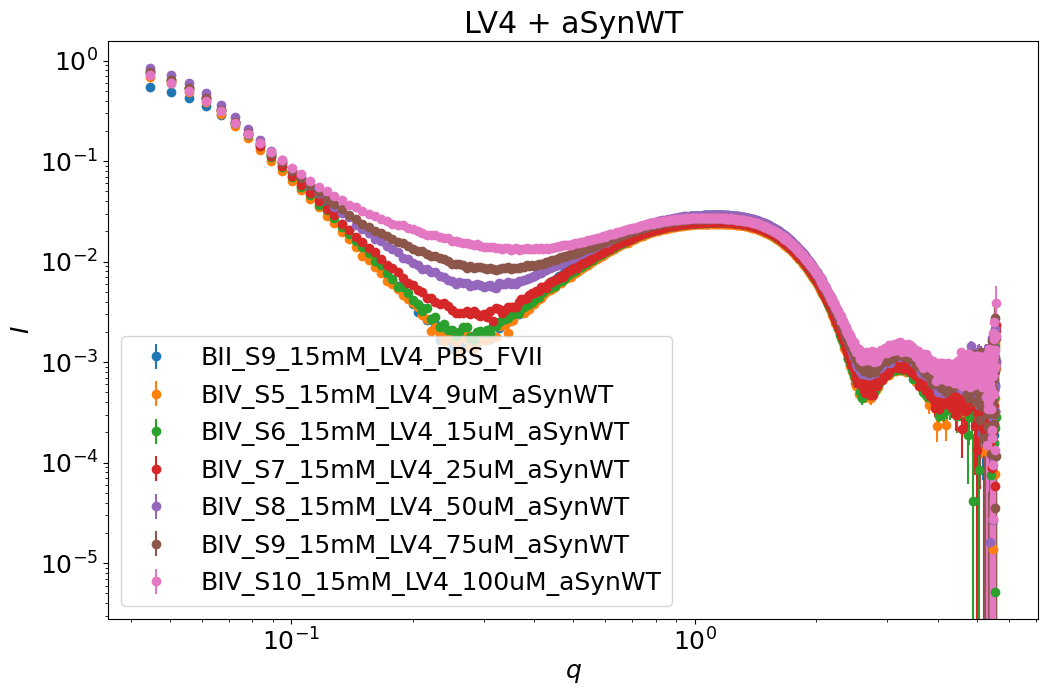

In [4]:
title = "LV4 + aSynWT"

who = [
    "BII_S9",
    # "BIV_S1",
    # "BIV_S2",
    # "BIV_S3",
    # "BIV_S4",
    "BIV_S5",
    "BIV_S6",
    "BIV_S7",
    "BIV_S8",
    "BIV_S9",
    "BIV_S10",   
]

BM29.plot_together(who, title)

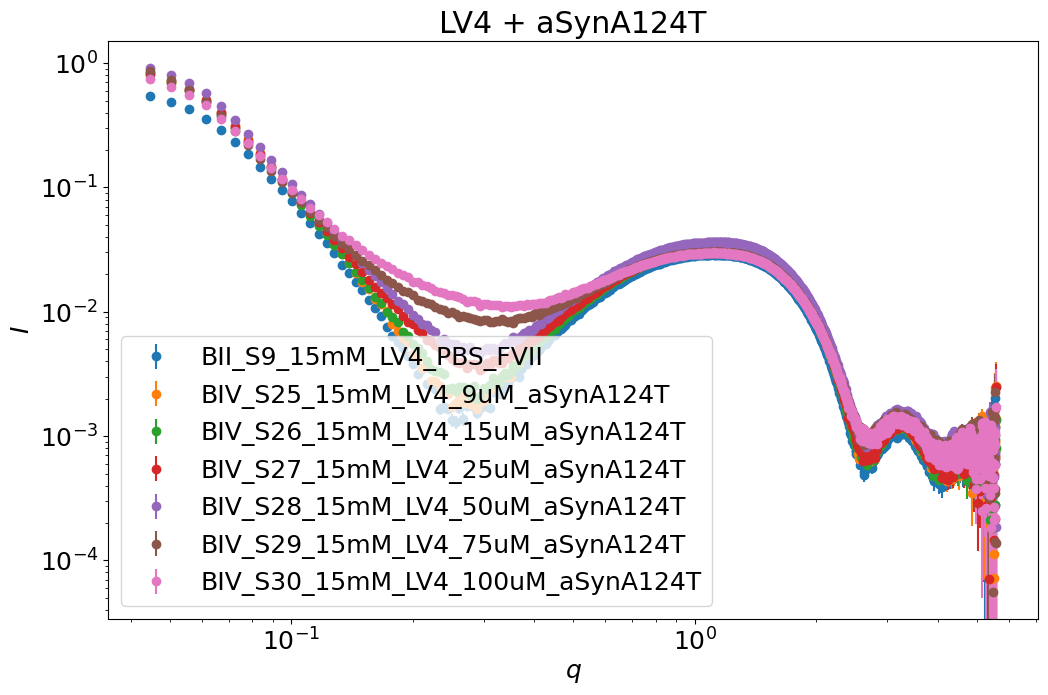

In [6]:
title = "LV4 + aSynA124T"

who = [
    "BII_S9",
    # "BIV_S21",
    # "BIV_S22",
    # "BIV_S23",
    # "BIV_S24",
    "BIV_S25",
    "BIV_S26",
    "BIV_S27",
    "BIV_S28",
    "BIV_S29",
    "BIV_S30",  
]

BM29.plot_together(who, title)

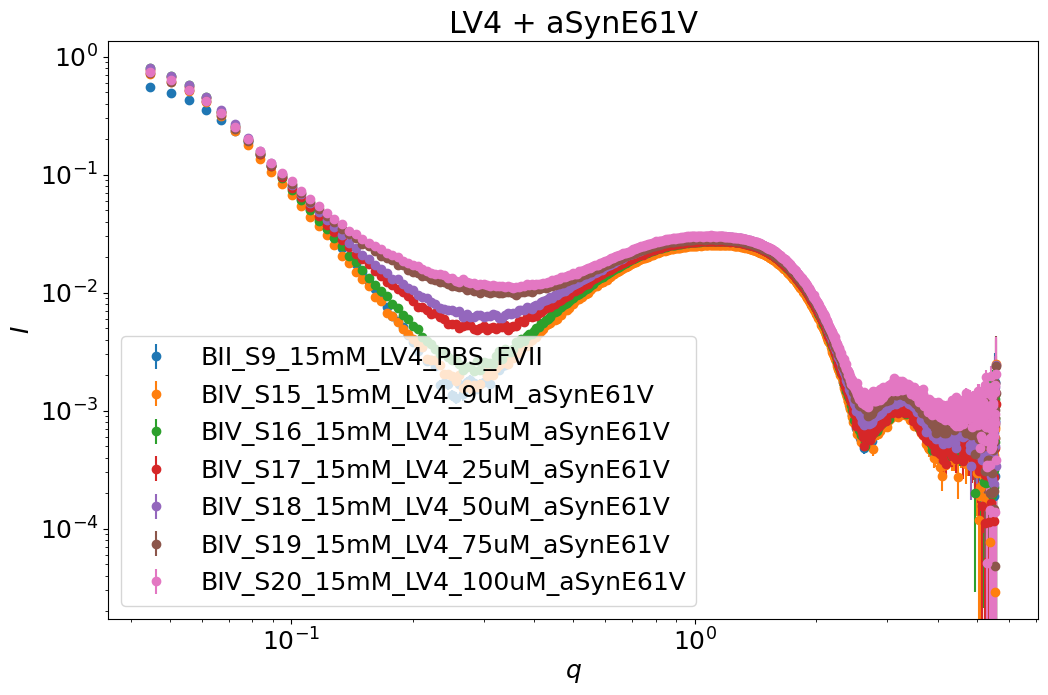

In [8]:
title = "LV4 + aSynE61V"

who = [
    "BII_S9",
    # "BIV_S11",
    # "BIV_S12",
    # "BIV_S13",
    # "BIV_S14",
    "BIV_S15",
    "BIV_S16",
    "BIV_S17",
    "BIV_S18",
    "BIV_S19",
    "BIV_S20",
]

BM29.plot_together(who, title)

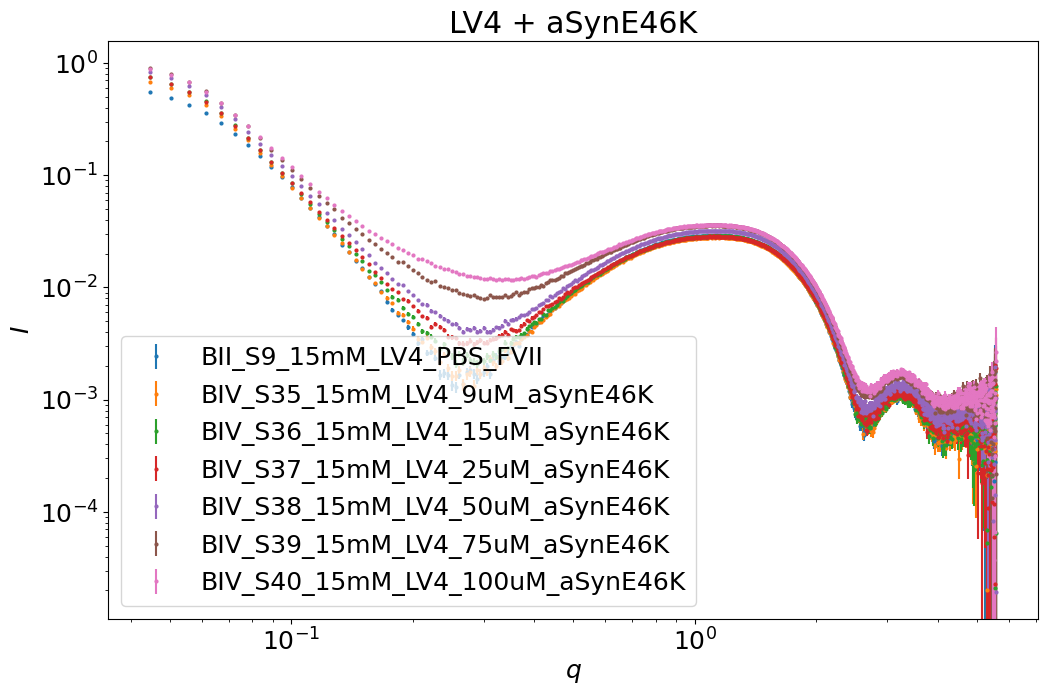

In [5]:
title = "LV4 + aSynE46K"

who = [
    "BII_S9",
    # "BIV_S31",
    # "BIV_S32",
    # "BIV_S33",
    # "BIV_S34",
    "BIV_S35",
    "BIV_S36",
    "BIV_S37",
    "BIV_S38",
    "BIV_S39",
    "BIV_S40",
]

BM29.plot_together(who, title)

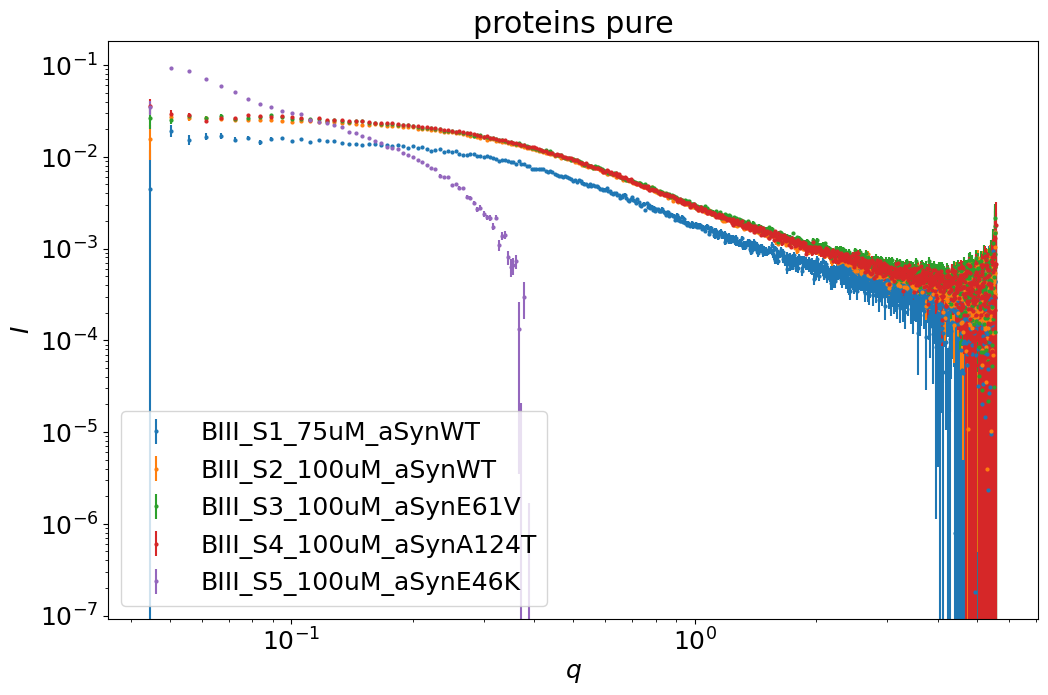

In [6]:
title = "proteins pure"

who = [
    "BIII_S1",
    "BIII_S2",
    "BIII_S3",
    "BIII_S4",
    "BIII_S5",
]

BM29.plot_together(who, title)